In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = pd.Series(
    iris.target,
    name="target"
)

In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (150, 4)
y shape: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [6]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [7]:

rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [8]:
print(rf_model)

RandomForestClassifier(random_state=42)


In [9]:
y_pred = rf_model.predict(X_test)

In [10]:
print(y_pred)

[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 2 1 0 2 0]


In [11]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.9


In [12]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


In [13]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [15]:
from sklearn.utils import resample

sample_1 = resample(
    X_train,
    y_train,
    replace=True,
    random_state=1
)

sample_2 = resample(
    X_train,
    y_train,
    replace=True,
    random_state=2
)

In [16]:
print("Sample 1:", sample_1[0].shape)
print("Sample 2:", sample_2[0].shape)

Sample 1: (120, 4)
Sample 2: (120, 4)


In [17]:
print("Unique rows in sample 1:", sample_1[0].drop_duplicates().shape[0])
print("Unique rows in sample 2:", sample_2[0].drop_duplicates().shape[0])

Unique rows in sample 1: 80
Unique rows in sample 2: 79


In [18]:
print("Number of trees:", len(rf_model.estimators_))

Number of trees: 100


In [19]:
tree_1 = rf_model.estimators_[0]

print(tree_1)

DecisionTreeClassifier(max_features='sqrt', random_state=1608637542)


In [20]:
tree_2 = rf_model.estimators_[1]

print(tree_2)

DecisionTreeClassifier(max_features='sqrt', random_state=1273642419)


In [21]:
print(type(tree_1))

<class 'sklearn.tree._classes.DecisionTreeClassifier'>


In [22]:
print(type(tree_2))

<class 'sklearn.tree._classes.DecisionTreeClassifier'>


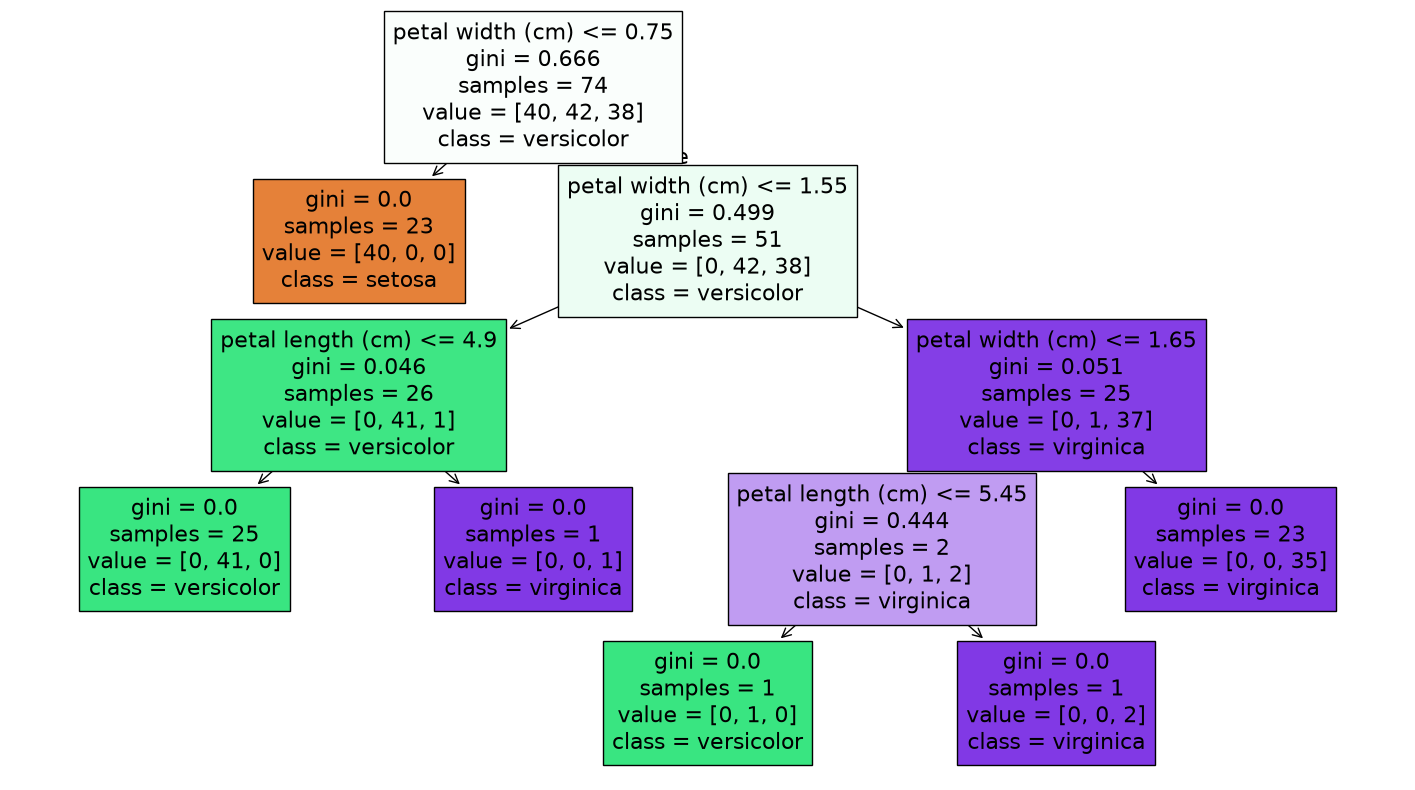

In [23]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 10))

plot_tree(
    tree_1,
    feature_names=X.columns,
    class_names=iris.target_names,
    filled=True
)

plt.show()

In [24]:
for i, tree in enumerate(rf_model.estimators_[:10]):
    print(f"Tree {i+1}: depth = {tree.get_depth()}")

Tree 1: depth = 4
Tree 2: depth = 6
Tree 3: depth = 4
Tree 4: depth = 5
Tree 5: depth = 5
Tree 6: depth = 5
Tree 7: depth = 5
Tree 8: depth = 5
Tree 9: depth = 5
Tree 10: depth = 5


In [25]:
sample = X_test.iloc[[0]]

print(sample)

    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
38                4.4               3.0                1.3               0.2


In [26]:
prediction = rf_model.predict(sample)

print("Final prediction:", prediction[0])
print("Flower:", iris.target_names[prediction[0]])

Final prediction: 0
Flower: setosa


In [27]:
tree_predictions = []

for tree in rf_model.estimators_:
    prediction = tree.predict(sample)[0]
    tree_predictions.append(int(prediction))

print(tree_predictions)

C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has fe

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
C:\Users\vaish\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has fe

In [28]:
tree_predictions = []

for tree in rf_model.estimators_:
    prediction = tree.predict(sample.values)[0]
    tree_predictions.append(int(prediction))

print(tree_predictions)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [29]:
from collections import Counter

votes = Counter(tree_predictions)

print(votes)

Counter({0: 100})


In [30]:
probabilities = rf_model.predict_proba(sample)

print(probabilities)

[[1. 0. 0.]]


In [31]:
print(rf_model.classes_)

[0 1 2]


In [32]:
print("predict:", rf_model.predict(sample))
print("probability:", rf_model.predict_proba(sample))

predict: [0]
probability: [[1. 0. 0.]]


In [33]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

             Feature  Importance
3   petal width (cm)    0.437185
2  petal length (cm)    0.431466
0  sepal length (cm)    0.116349
1   sepal width (cm)    0.015000


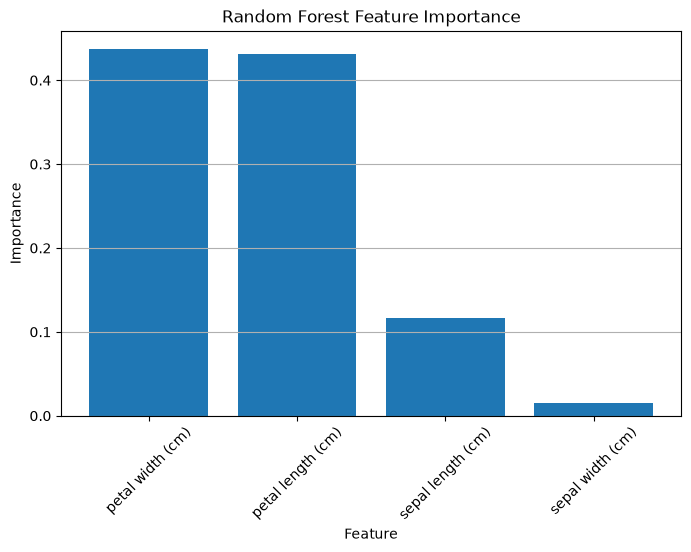

In [34]:
plt.figure(figsize=(8, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

In [35]:
tree_counts = [1, 5, 10, 25, 50, 100, 200]

for n in tree_counts:
    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    rf.fit(X_train, y_train)

    train_acc = rf.score(X_train, y_train)
    test_acc = rf.score(X_test, y_test)

    print(
        f"n_estimators={n}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

n_estimators=1: Train=0.992, Test=0.967
n_estimators=5: Train=1.000, Test=0.933
n_estimators=10: Train=1.000, Test=0.967
n_estimators=25: Train=1.000, Test=0.933
n_estimators=50: Train=1.000, Test=0.900
n_estimators=100: Train=1.000, Test=0.900
n_estimators=200: Train=1.000, Test=0.900


In [36]:
feature_values = [1, 2, 3, 4]

for value in feature_values:

    rf = RandomForestClassifier(
        n_estimators=100,
        max_features=value,
        random_state=42
    )

    rf.fit(X_train, y_train)

    train_acc = rf.score(X_train, y_train)
    test_acc = rf.score(X_test, y_test)

    print(
        f"max_features={value}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

max_features=1: Train=1.000, Test=0.933
max_features=2: Train=1.000, Test=0.900
max_features=3: Train=1.000, Test=0.933
max_features=4: Train=1.000, Test=0.967


In [37]:
depth_values = [1, 2, 3, 4, 5, None]

for depth in depth_values:

    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    rf.fit(X_train, y_train)

    train_acc = rf.score(X_train, y_train)
    test_acc = rf.score(X_test, y_test)

    print(
        f"max_depth={depth}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

max_depth=1: Train=0.967, Test=0.967
max_depth=2: Train=0.975, Test=0.900
max_depth=3: Train=0.983, Test=0.967
max_depth=4: Train=1.000, Test=0.967
max_depth=5: Train=1.000, Test=0.933
max_depth=None: Train=1.000, Test=0.900


In [38]:
split_values = [2, 5, 10, 20]

for value in split_values:

    rf = RandomForestClassifier(
        n_estimators=100,
        min_samples_split=value,
        random_state=42
    )

    rf.fit(X_train, y_train)

    train_acc = rf.score(X_train, y_train)
    test_acc = rf.score(X_test, y_test)

    print(
        f"min_samples_split={value}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

min_samples_split=2: Train=1.000, Test=0.900
min_samples_split=5: Train=0.983, Test=0.967
min_samples_split=10: Train=0.983, Test=0.967
min_samples_split=20: Train=0.983, Test=0.967


In [39]:
leaf_values = [1, 2, 5, 10]

for value in leaf_values:

    rf = RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=value,
        random_state=42
    )

    rf.fit(X_train, y_train)

    train_acc = rf.score(X_train, y_train)
    test_acc = rf.score(X_test, y_test)

    print(
        f"min_samples_leaf={value}: "
        f"Train={train_acc:.3f}, "
        f"Test={test_acc:.3f}"
    )

min_samples_leaf=1: Train=1.000, Test=0.900
min_samples_leaf=2: Train=0.983, Test=0.967
min_samples_leaf=5: Train=0.975, Test=0.967
min_samples_leaf=10: Train=0.975, Test=0.967


In [40]:
rf_oob = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42
)

rf_oob.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the followi

In [41]:
print("OOB Score:", rf_oob.oob_score_)

OOB Score: 0.9416666666666667


In [42]:
test_accuracy = rf_oob.score(X_test, y_test)

print("OOB Score:", rf_oob.oob_score_)
print("Test Accuracy:", test_accuracy)

OOB Score: 0.9416666666666667
Test Accuracy: 0.9


In [43]:
oob_pred = rf_oob.oob_decision_function_

print(oob_pred[:5])

[[1.         0.         0.        ]
 [0.         0.74285714 0.25714286]
 [0.         0.90909091 0.09090909]
 [1.         0.         0.        ]
 [0.         1.         0.        ]]


In [44]:
final_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

final_rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [45]:
y_pred = final_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Accuracy: 0.9

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [46]:
new_flower = pd.DataFrame({
    "sepal length (cm)": [5.1],
    "sepal width (cm)": [3.5],
    "petal length (cm)": [1.4],
    "petal width (cm)": [0.2]
})

prediction = final_rf.predict(new_flower)

print("Predicted class:", prediction[0])
print("Predicted flower:", iris.target_names[prediction[0]])

Predicted class: 0
Predicted flower: setosa


In [47]:
probability = final_rf.predict_proba(new_flower)

print(probability)

[[1. 0. 0.]]
